In [2]:
import numpy as np
import pandas as pd
import argparse
import os
from itertools import combinations
from collections import defaultdict
from upsetplot import from_memberships, UpSet
from upsetplot import plot
import matplotlib.pyplot as plt
import logging
import csv
from itertools import combinations
from collections import defaultdict
from matplotlib import pyplot
from upsetplot import from_contents, plot
from upsetplot import from_memberships, UpSet

In [3]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# def find_common_sequences(samples):
#     combos = []
#     counts = []

#     # Iterate through all combinations of sample keys (categories)
#     for i in range(1, len(samples) + 1):
#         for combo in combinations(samples.keys(), i):
#             # Find common sequences and their count
#             common_seqs = set.intersection(*(set(samples[sample]) for sample in combo))
#             combos.append(list(combo))  # Store the combination as a list
#             counts.append(len(common_seqs))  # Store the count of common sequences

#     return combos, counts


def format_memberships(sample_sequences, result):
    formatted = []
    data = []

def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) > 0)]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df



In [72]:


base_path = "../../../../2nd_6samples_output"

#dataset2
sample_names = [
    "SRR18078867", "SRR18078868", "SRR18078869", 
    "SRR18078870", "SRR18078871", "SRR18078872"
]



read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  



DataFrame SRR18078867 has 73721 lines.
DataFrame SRR18078868 has 49594 lines.
DataFrame SRR18078869 has 38450 lines.
DataFrame SRR18078870 has 72808 lines.
DataFrame SRR18078871 has 38747 lines.
DataFrame SRR18078872 has 50518 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.192554,0.511739;0.707446x0.368261)
186577


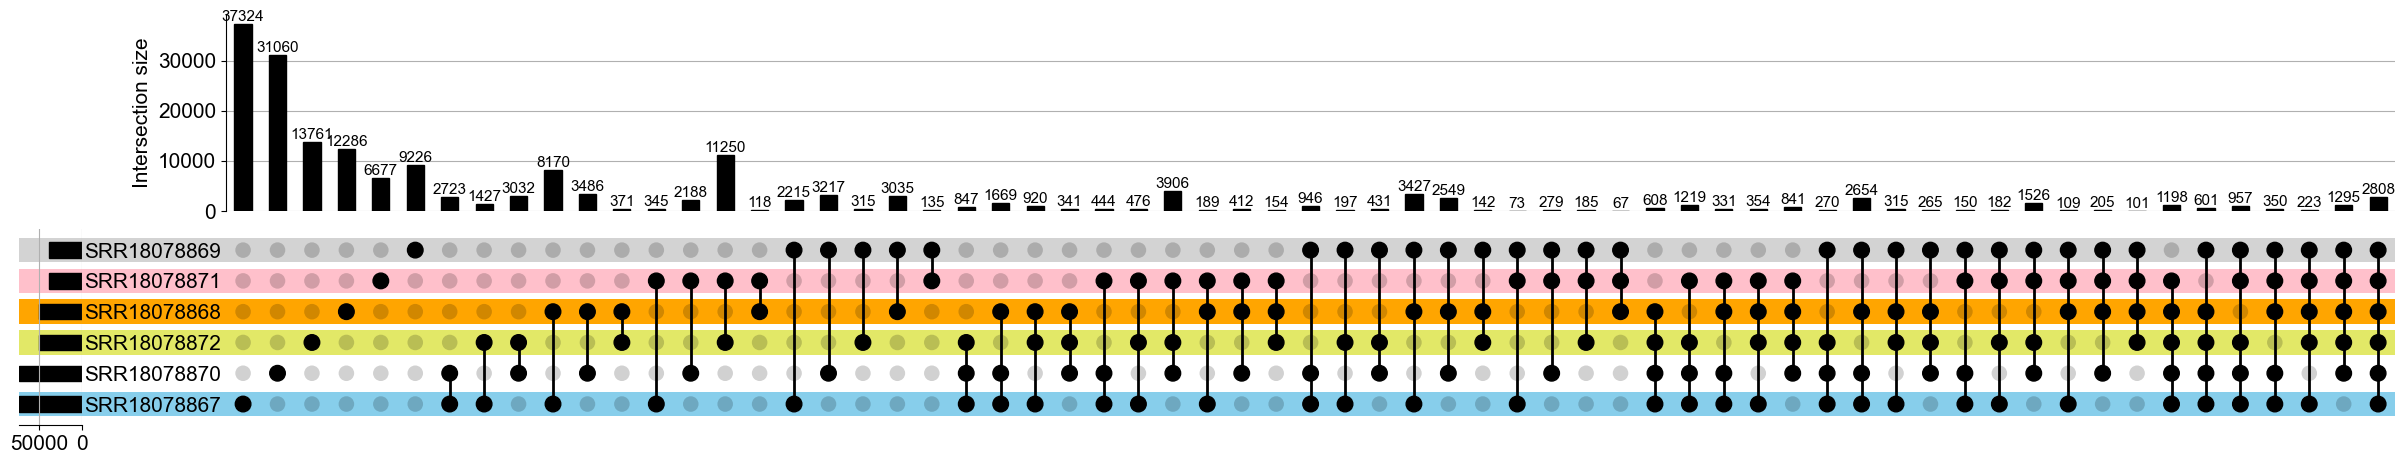

In [73]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)

# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 11
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=11
        )
        h += height
print(h)
# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


# for text in bar_ax.texts:  
#     print(text)
#     text.set_fontproperties(arial_font_in)


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset2.pdf", format="pdf", bbox_inches="tight")


In [74]:


#base_path = "../../../../2nd_6samples_output"
base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
sample_names = [
    "SRR20723831", "SRR20723832", "SRR20723833"
]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  



DataFrame SRR20723831 has 1873660 lines.
DataFrame SRR20723832 has 1793252 lines.
DataFrame SRR20723833 has 1952763 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.452465,0.381765;0.447535x0.498235)
3602055


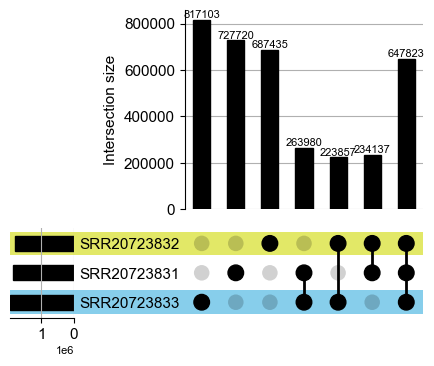

In [75]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=11)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)

# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])

for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)

plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset3.pdf", format="pdf", bbox_inches="tight")


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

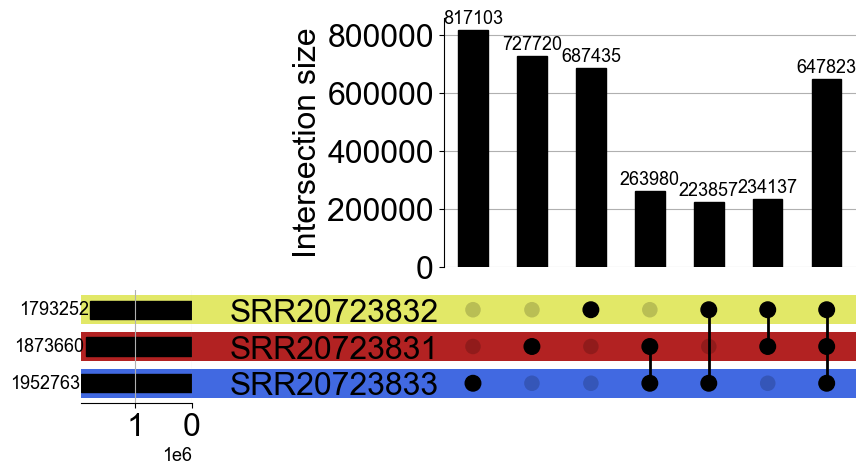

In [76]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=23)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)

# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 13
ax = plot(upset_data, show_counts=True)
# ax_bars = ax["intersections"]
# print(ax_bars)
# h = 0
# for bar in ax_bars.patches:
#     height = bar.get_height()
#     if height > 0:
#         ax_bars.text(
#             bar.get_x() + bar.get_width() / 2,
#             height,
#             f"{int(height)}",
#             ha="center",
#             va="bottom"
#         )
#         h += height
# print(h)

# plt.show()

fig = plt.gcf()
fig.set_size_inches(10, 5)
axes = fig.get_axes()


colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])

# for text in bar_ax.texts:  
#     print(text)
#     text.set_fontproperties(arial_font_in)

for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)

plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure4_C.pdf", format="pdf", bbox_inches="tight")

In [77]:


#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
sample_names = [
    "SRR25896993", "SRR25896994", "SRR25896995"
]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]

read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  



DataFrame SRR25896993 has 321739 lines.
DataFrame SRR25896994 has 322958 lines.
DataFrame SRR25896995 has 358302 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.452465,0.381765;0.447535x0.498235)
748943


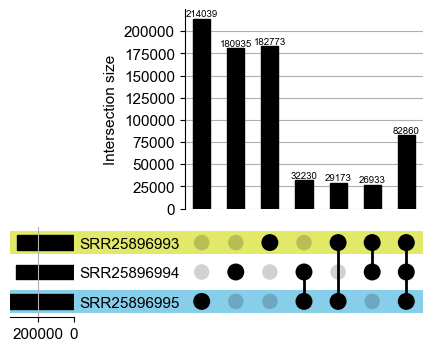

In [78]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=11)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)

# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 7
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()

# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset4.pdf", format="pdf", bbox_inches="tight")


In [79]:

#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
# #dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
sample_names = [
    "SRR12412943", "SRR12412944"
]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']
df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  




DataFrame SRR12412943 has 124897 lines.
DataFrame SRR12412944 has 98341 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.619681,0.315333;0.280319x0.564667)
178571


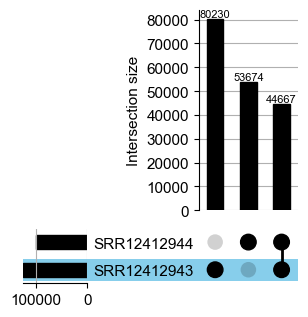

In [80]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=11)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)

# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset6.pdf", format="pdf", bbox_inches="tight")


In [4]:

#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
sample_names = [
    "DRR037104", "DRR037108","DRR037112"
]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']
df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
keys_list = list(all_sequences.keys())
print(keys_list)
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  



DataFrame DRR037104 has 786255 lines.
DataFrame DRR037108 has 687780 lines.
DataFrame DRR037112 has 744932 lines.
['DRR037104', 'DRR037108', 'DRR037112']


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.452465,0.381765;0.447535x0.498235)
1759510


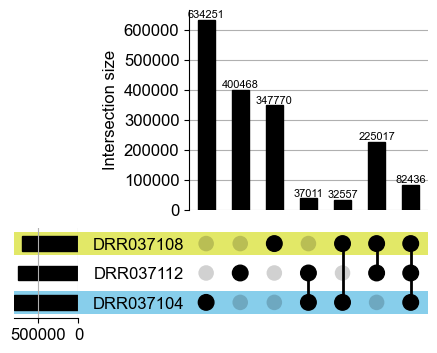

In [7]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=12)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)
# # Example data
# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


# upset = UpSet(example)
# upset.plot()
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


# for text in bar_ax.texts:  
#     # print(text)
#     text.set_fontproperties(arial_font_in)


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset7.pdf", format="pdf", bbox_inches="tight")


In [83]:


#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
sample_names = [
    "SRR1638859", "SRR1638860"
]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']
df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  




DataFrame SRR1638859 has 507293 lines.
DataFrame SRR1638860 has 241555 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.619681,0.315333;0.280319x0.564667)
629486


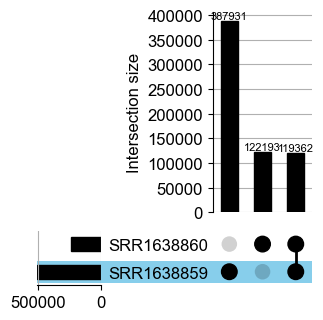

In [84]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)
# # Example data
# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


# upset = UpSet(example)
# upset.plot()
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


# for text in bar_ax.texts:  
#     print(text)
#     text.set_fontproperties(arial_font_in)


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset8.pdf", format="pdf", bbox_inches="tight")


In [85]:


#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
#base_path = "../../../../9th_12samples_output"
base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
sample_names = [
    "SRR943111", "SRR943112"
]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']
df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  



DataFrame SRR943111 has 181148 lines.
DataFrame SRR943112 has 157054 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

Axes(0.619681,0.315333;0.280319x0.564667)
250107


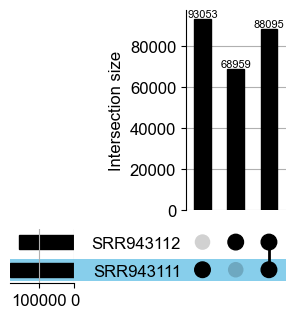

In [86]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)
# # Example data
# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


# upset = UpSet(example)
# upset.plot()
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


# for text in bar_ax.texts:  
#     print(text)
#     text.set_fontproperties(arial_font_in)


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset10.pdf", format="pdf", bbox_inches="tight")


In [87]:


#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
#base_path = "../../../../9th_12samples_output"
# base_path = "../../../../10th_2samples_output"
base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
sample_names = [
    "SRR684065", "SRR684066","SRR684086"
]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']
df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  



DataFrame SRR684065 has 13151 lines.
DataFrame SRR684066 has 22004 lines.
DataFrame SRR684086 has 18043 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


Axes(0.452465,0.381765;0.447535x0.498235)
43804


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

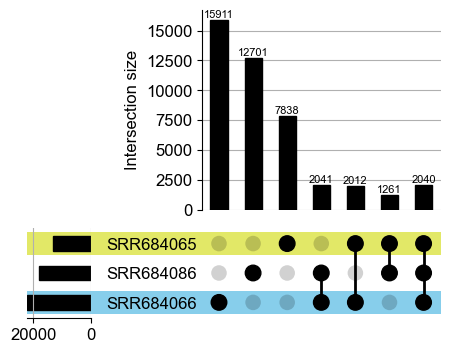

In [88]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)
# # Example data
# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


# upset = UpSet(example)
# upset.plot()
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


# for text in bar_ax.texts:  
#     print(text)
#     text.set_fontproperties(arial_font_in)


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset11.pdf", format="pdf", bbox_inches="tight")


In [89]:


#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../9th_12samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
# base_path = "../../../../12th_9samples_output"
base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
# #dataset12
# sample_names = [
#     "SRR9851810", "SRR9851811","SRR9851812","SRR9851813","SRR9851814","SRR9851815",
#     "SRR9851816","SRR9851817","SRR9851818"

# ]
#dataset13
sample_names = [
    "SRR8760721", "SRR8760722","SRR8760723"
]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']
df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
# read_csv_files(ecoli_names, df_ecoli, base_path, read_columns)
# read_csv_files(bifi_names + ecoli_names, df_all, base_path, read_columns)
#i = 1
# for name, df in df_bifi.items():
#     print(f"DataFrame for {name}:")
#     if 'sequence' in df.columns:
#         print(df['sequence'])  # Check if sequence column has data
#     else:
#         print("No 'sequence' column found in this DataFrame.")
all_sequences = {name: list(seq for seq in df['sequence']) for name, df in df_all_with_match.items()}
# print(all_sequences[name])
upset_data = from_contents(all_sequences)
# print(upset_data)
# plot(example)  
# pyplot.show()  
# pyplot.savefig("../../../../figure5_dataset2.png")  




DataFrame SRR8760721 has 1140 lines.
DataFrame SRR8760722 has 2773 lines.
DataFrame SRR8760723 has 3584 lines.


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


Axes(0.452465,0.381765;0.447535x0.498235)
6795


/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

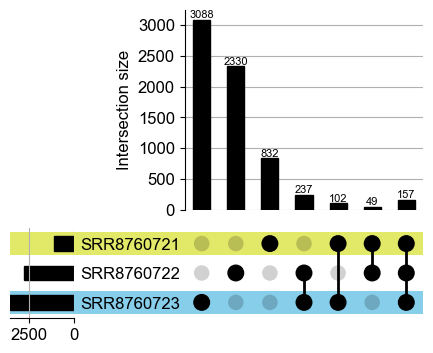

In [90]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=1)
# # Example data
# example = from_memberships(
#     [['A'], ['B'], ['A','B'], ['C'], ['A','C']],
#     [10, 8, 5, 7, 4]
# )


# upset = UpSet(example)
# upset.plot()
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 8
ax = plot(upset_data, show_counts=False)
ax_bars = ax["intersections"]
print(ax_bars)
h = 0
for bar in ax_bars.patches:
    height = bar.get_height()
    if height > 0:
        ax_bars.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom"
        )
        h += height
print(h)

# plt.show()

fig = plt.gcf()
axes = fig.get_axes()


# colors = ["royalblue", "firebrick", "#E2E867", "orange", "purple"]
colors = ["skyblue", "white","#E2E867","orange", "pink", "lightgray"]
bar_ax = axes[0]   

for i, patch in enumerate(bar_ax.patches):
    patch.set_facecolor(colors[i % len(colors)])


# for text in bar_ax.texts:  
#     print(text)
#     text.set_fontproperties(arial_font_in)


for ax in axes:
    ax.set_title(ax.get_title(), fontproperties=arial_font)
    ax.set_xlabel(ax.get_xlabel(), fontproperties=arial_font)
    ax.set_ylabel(ax.get_ylabel(), fontproperties=arial_font)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(arial_font)

    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_fontproperties(arial_font)


plt.legend(prop=arial_font, title_fontproperties=arial_font)
plt.legend().set_visible(False)
plt.tight_layout()
# plt.show()
plt.savefig("figure5_dataset13.pdf", format="pdf", bbox_inches="tight")
